In [1]:
from pathlib import Path
import os

import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch

In [4]:
dir_path=Path().cwd().parent 

data_dir_path=dir_path/'data/severstal-steel-defect-detection'
assert data_dir_path.exists()

images_train_dir=data_dir_path/'train_images'

In [6]:
train_df=pd.read_csv(data_dir_path/'train.csv')
train_df.head()

,ImageId,ClassId,EncodedPixels
0,0002cc93b.jpg,1,29102 12 29346 24 29602 24 29858 24 30114 24 3...
1,0007a71bf.jpg,3,18661 28 18863 82 19091 110 19347 110 19603 11...
2,000a4bcdd.jpg,1,37607 3 37858 8 38108 14 38359 20 38610 25 388...
3,000f6bf48.jpg,4,131973 1 132228 4 132483 6 132738 8 132993 11 ...
4,0014fce06.jpg,3,229501 11 229741 33 229981 55 230221 77 230468...


In [7]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7095 entries, 0 to 7094
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   ImageId        7095 non-null   str  
 1   ClassId        7095 non-null   int64
 2   EncodedPixels  7095 non-null   str  
dtypes: int64(1), str(2)
memory usage: 166.4 KB


In [8]:
train_df.ClassId.value_counts()

ClassId
3    5150
1     897
4     801
2     247
Name: count, dtype: int64

In [9]:
all_images=sorted(os.listdir(images_train_dir))
len(all_images)

12568

In [10]:
images_df = pd.DataFrame({
    "ImageId": sorted(all_images)
})

images_df["has_defect"] = images_df["ImageId"].isin(train_df['ImageId']).astype(int)


images_df=images_df.merge(
    train_df,
    on='ImageId',
    how='left'
)

images_df['ClassId']=images_df['ClassId'].fillna(0)
images_df['EncodedPixels']=images_df['EncodedPixels'].fillna('0')

images_df.head()

,ImageId,has_defect,ClassId,EncodedPixels
0,0002cc93b.jpg,1,1.0,29102 12 29346 24 29602 24 29858 24 30114 24 3...
1,00031f466.jpg,0,0.0,0
2,000418bfc.jpg,0,0.0,0
3,000789191.jpg,0,0.0,0
4,0007a71bf.jpg,1,3.0,18661 28 18863 82 19091 110 19347 110 19603 11...


In [11]:
sample=images_df[images_df['has_defect']==1].sample()
sample

,ImageId,has_defect,ClassId,EncodedPixels
3394,42996bbcf.jpg,1,3.0,333192 4 333446 9 333701 13 333955 15 334206 1...


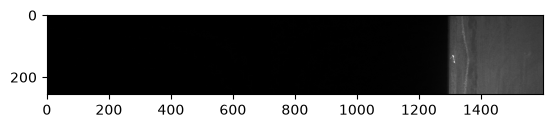

In [12]:
img=cv2.imread(images_train_dir/sample.ImageId.item())
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

plt.imshow(img, cmap='gray')
plt.show()

In [19]:
img.shape[0]*img.shape[1]

409600

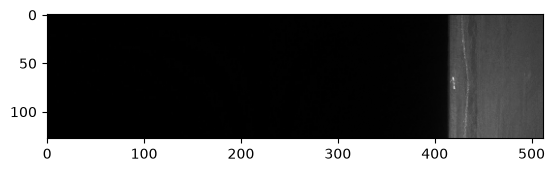

In [18]:
img_resized=cv2.resize(img, (512, 128))

plt.imshow(img_resized, cmap='gray')
plt.show()

In [20]:
img_resized.shape[0]*img_resized.shape[1]

65536

In [120]:
pairs=np.fromstring(sample.EncodedPixels.item(), sep=" ", dtype=np.int64).reshape(-1, 2)
mask=np.zeros(img.shape[0]*img.shape[1], dtype=np.uint8)

for start, length in pairs:
    start-=1

    mask[start:start+length]=1

mask=mask.reshape(img.shape[0], img.shape[1], order='F')

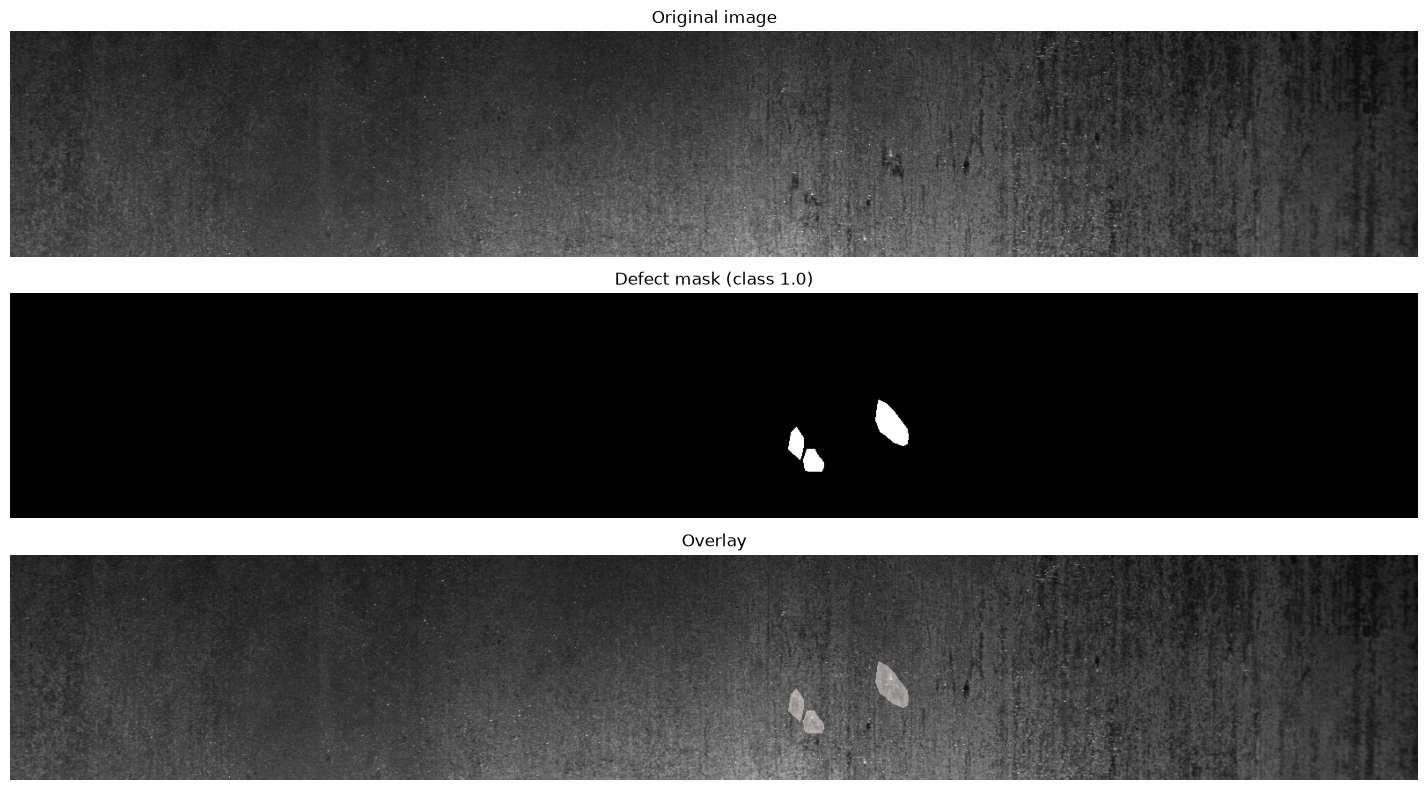

In [121]:
fig, axes = plt.subplots(3, 1, figsize=(16, 8))

axes[0].imshow(img, cmap="gray")
axes[0].set_title("Original image")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title(f"Defect mask (class {sample['ClassId'].item()})")

axes[2].imshow(img, cmap="gray")
axes[2].imshow(
    np.ma.masked_where(mask == 0, mask),
    cmap="Reds",
    alpha=0.5
)
axes[2].set_title("Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [130]:
img.shape

(256, 1600)

In [129]:
t=torch.from_numpy(img).float() / 255.0

t.unsqueeze(1).shape

torch.Size([256, 1, 1600])

In [136]:
img.shape

(256, 1600)

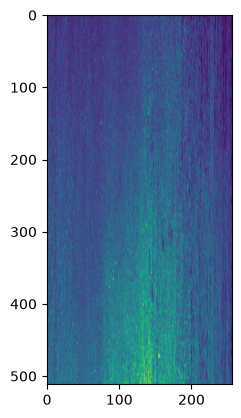

In [135]:
img_resized=cv2.resize(img, (256, 512))

plt.imshow(img_resized)